In [15]:
.libPaths(c("/home/amithsiri/R/library", .libPaths()))
library(Seurat)

In [16]:
library(Seurat)
library(Matrix)
library(dplyr)
library(ggplot2)
library(patchwork)

packageVersion("Seurat")

[1] ‘5.5.1’

In [17]:
# Cell 3: Locate the NPZ matrix and related files

search_root <- "/home/amithsiri/projects"

npz_files <- list.files(
  search_root,
  pattern = "GSE200164_counts_csr\\.npz$",
  recursive = TRUE,
  full.names = TRUE
)

cat("NPZ file found:\n")
print(npz_files)

if (length(npz_files) == 1) {
  data_dir <- dirname(npz_files[1])

  cat("\nContaining directory:\n")
  print(data_dir)

  cat("\nFiles in the same directory:\n")
  print(list.files(data_dir, full.names = TRUE))
}

NPZ file found:
[1] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache/GSE200164_counts_csr.npz"

Containing directory:
[1] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache"

Files in the same directory:
[1] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache/GSE200164_barcodes.txt"        
[2] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache/GSE200164_cell_metadata.csv"   
[3] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache/GSE200164_counts_csr.npz"      
[4] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache/GSE200164_counts.mtx"          
[5] "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache/GSE200164_genes.txt"           
[6] "/home/amithsiri/projects/Summer-Project

In [18]:
# Cell 4: Ask Python to inspect the SciPy sparse matrix

npz_path <- npz_files[1]

python_code <- sprintf(
  paste(
    "import scipy.sparse as sp",
    "x = sp.load_npz(r'''%s''')",
    "print('Python class:', type(x))",
    "print('Shape:', x.shape)",
    "print('Nonzero values:', x.nnz)",
    "print('Data type:', x.dtype)",
    "print('Sparse format:', x.getformat())",
    sep = "\n"
  ),
  npz_path
)

output <- system2(
  "python3",
  args = c("-c", shQuote(python_code)),
  stdout = TRUE,
  stderr = TRUE
)

cat(paste(output, collapse = "\n"))

Python class: <class 'scipy.sparse._csr.csr_matrix'>
Shape: (19689, 70391)
Nonzero values: 126603213
Data type: float64
Sparse format: csr

In [19]:
# Cell 5: Convert SciPy CSR matrix to Matrix Market format for R

cache_dir <- "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache"

npz_path <- file.path(cache_dir, "GSE200164_counts_csr.npz")
mtx_path <- file.path(cache_dir, "GSE200164_counts.mtx")

python_code <- sprintf(
  paste(
    "import scipy.sparse as sp",
    "from scipy.io import mmwrite",
    "x = sp.load_npz(r'''%s''')",
    "print('Loaded:', x.shape, 'nnz=', x.nnz, 'format=', x.getformat())",
    "mmwrite(r'''%s''', x)",
    "print('Wrote Matrix Market file')",
    sep = "\n"
  ),
  npz_path,
  mtx_path
)

output <- system2(
  "python3",
  args = c("-c", shQuote(python_code)),
  stdout = TRUE,
  stderr = TRUE
)

cat(paste(output, collapse = "\n"))

Loaded: (19689, 70391) nnz= 126603213 format= csr
Wrote Matrix Market file

In [20]:
# Cell 6: Load sparse expression matrix into R

suppressPackageStartupMessages({
  library(Matrix)
  library(readr)
})

cache_dir <- "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sparse_cache"

mtx_path <- file.path(cache_dir, "GSE200164_counts.mtx")
genes_path <- file.path(cache_dir, "GSE200164_genes.txt")
barcodes_path <- file.path(cache_dir, "GSE200164_barcodes.txt")
metadata_path <- file.path(cache_dir, "GSE200164_cell_metadata.csv")

# Read the sparse gene-by-cell matrix.
counts <- readMM(mtx_path)

# Convert from coordinate-triplet format to column-compressed sparse format.
# Seurat works more efficiently with a dgCMatrix.
counts <- as(counts, "CsparseMatrix")

# Read row and column identifiers.
genes <- readLines(genes_path)
barcodes <- readLines(barcodes_path)

# Verify orientation and dimensions before assigning names.
stopifnot(nrow(counts) == length(genes))
stopifnot(ncol(counts) == length(barcodes))

rownames(counts) <- genes
colnames(counts) <- barcodes

cat(
  "Loaded matrix:\n",
  format(nrow(counts), big.mark = ","), "genes ×",
  format(ncol(counts), big.mark = ","), "cells\n",
  "Nonzero values:", format(length(counts@x), big.mark = ","), "\n",
  "Class:", class(counts)[1], "\n"
)

Loaded matrix:
 19,689 genes × 70,391 cells
 Nonzero values: 126,603,213 
 Class: dgCMatrix 


In [23]:
# Load per-cell metadata and align it to the sparse matrix columns
sparse_dir <- "../results/figure1d/sparse_cache"

metadata <- utils::read.csv(
  file.path(sparse_dir, "GSE200164_cell_metadata.csv"),
  stringsAsFactors = FALSE,
  check.names = FALSE
)

stopifnot("cell" %in% colnames(metadata), !anyDuplicated(metadata$cell))

rownames(metadata) <- metadata$cell
metadata <- metadata[barcodes, , drop = FALSE]

stopifnot(
  identical(rownames(metadata), barcodes),
  !anyNA(metadata$sample_id)
)

print(colnames(metadata))

[1] "cell"       "sample_id"  "gsm"        "title"      "diagnosis" 
[6] "sex"        "age"        "n_cells"    "orig.ident"


In [24]:
# Cell 7: Assign names and inspect metadata alignment

# Convert triplet sparse format to compressed-column format,
# which is more efficient for Seurat
counts <- as(counts, "CsparseMatrix")

stopifnot(nrow(counts) == length(genes))
stopifnot(ncol(counts) == length(barcodes))

rownames(counts) <- genes
colnames(counts) <- barcodes

cat("Matrix class after conversion:", class(counts), "\n")
cat("First 6 genes:\n")
print(head(rownames(counts)))

cat("\nFirst 6 matrix barcodes:\n")
print(head(colnames(counts)))

cat("\nMetadata column names:\n")
print(colnames(metadata))

cat("\nFirst 6 metadata rows:\n")
print(head(metadata))

cat("\nMetadata row names:\n")
print(head(rownames(metadata)))

cat("\nDuplicate genes:", sum(duplicated(rownames(counts))), "\n")
cat("Duplicate matrix barcodes:", sum(duplicated(colnames(counts))), "\n")

cat("\nCounts summary:\n")
print(summary(as.numeric(counts@x)))

Matrix class after conversion: dgCMatrix 
First 6 genes:
[1] "A1BG"     "A1BG-AS1" "A2M"      "A2M-AS1"  "A4GALT"   "AAAS"    

First 6 matrix barcodes:
[1] "A1_AAACCTGGTTGGTGGA-1" "A1_AAACGGGAGAGACGAA-1" "A1_AAAGCAAAGACTTGAA-1"
[4] "A1_AAAGCAAAGGCAGTCA-1" "A1_AACACGTAGCCAGAAC-1" "A1_AACACGTGTCTAGTGT-1"

Metadata column names:
[1] "cell"       "sample_id"  "gsm"        "title"      "diagnosis" 
[6] "sex"        "age"        "n_cells"    "orig.ident"

First 6 metadata rows:
                                       cell sample_id        gsm          title
A1_AAACCTGGTTGGTGGA-1 A1_AAACCTGGTTGGTGGA-1        A1 GSM6016346 CSF_Healthy_A1
A1_AAACGGGAGAGACGAA-1 A1_AAACGGGAGAGACGAA-1        A1 GSM6016346 CSF_Healthy_A1
A1_AAAGCAAAGACTTGAA-1 A1_AAAGCAAAGACTTGAA-1        A1 GSM6016346 CSF_Healthy_A1
A1_AAAGCAAAGGCAGTCA-1 A1_AAAGCAAAGGCAGTCA-1        A1 GSM6016346 CSF_Healthy_A1
A1_AACACGTAGCCAGAAC-1 A1_AACACGTAGCCAGAAC-1        A1 GSM6016346 CSF_Healthy_A1
A1_AACACGTGTCTAGTGT-1 A1_AACACGTGTCTAGTGT-

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
4.000e-05 9.641e-01 9.855e-01 2.869e+00 1.966e+00 2.743e+03 


In [25]:
# Cell 8: Verify and enforce metadata alignment

stopifnot(!anyDuplicated(metadata$cell))
stopifnot(!anyDuplicated(colnames(counts)))

cat("Cells identical and already in the same order:\n")
print(identical(metadata$cell, colnames(counts)))

cat("\nAll matrix cells present in metadata:\n")
print(all(colnames(counts) %in% metadata$cell))

cat("\nAll metadata cells present in matrix:\n")
print(all(metadata$cell %in% colnames(counts)))

# Reorder metadata explicitly to match the matrix
metadata <- metadata[
  match(colnames(counts), metadata$cell),
  ,
  drop = FALSE
]

rownames(metadata) <- metadata$cell

stopifnot(identical(rownames(metadata), colnames(counts)))
stopifnot(!anyNA(metadata$sample_id))

cat("\nMetadata successfully aligned.\n")
cat("Number of cells:", nrow(metadata), "\n")
cat("Number of samples:", length(unique(metadata$sample_id)), "\n")

cat("\nCells per diagnosis:\n")
print(table(metadata$diagnosis))

cat("\nCells per sample, first 10:\n")
print(head(sort(table(metadata$sample_id), decreasing = TRUE), 10))

Cells identical and already in the same order:
[1] TRUE

All matrix cells present in metadata:
[1] TRUE

All metadata cells present in matrix:
[1] TRUE

Metadata successfully aligned.
Number of cells: 70391 
Number of samples: 59 

Cells per diagnosis:

Healthy  MCI/AD 
  54267   16124 

Cells per sample, first 10:

  F2   A2   H5   G2   E3   H3   C1   H1   E1   D2 
4645 4169 3672 2542 2467 2421 2362 2249 2219 2206 


In [26]:
# Cell 9: Basic count-matrix diagnostics

set.seed(123)

nonzero_values <- counts@x

cat("Proportion of nonzero values that are exact integers:\n")
print(mean(abs(nonzero_values - round(nonzero_values)) < 1e-8))

cat("\nLibrary-size summary:\n")
print(summary(Matrix::colSums(counts)))

cat("\nDetected-gene summary:\n")
print(summary(Matrix::colSums(counts > 0)))

cat("\nExample library sizes:\n")
print(head(Matrix::colSums(counts)))

Proportion of nonzero values that are exact integers:


[1] 0.01695361

Library-size summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  469.8  3224.5  4376.1  5159.9  5902.6 42120.4 

Detected-gene summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    202    1344    1691    1799    2071    6687 

Example library sizes:
A1_AAACCTGGTTGGTGGA-1 A1_AAACGGGAGAGACGAA-1 A1_AAAGCAAAGACTTGAA-1 
             7390.993              4564.215              4945.611 
A1_AAAGCAAAGGCAGTCA-1 A1_AACACGTAGCCAGAAC-1 A1_AACACGTGTCTAGTGT-1 
             5748.716             11940.072              5950.696 


In [27]:
# Create Seurat object from the corrected count matrix

library(Seurat)
library(Matrix)

metadata <- metadata[
  match(colnames(counts), metadata$cell),
  ,
  drop = FALSE
]

rownames(metadata) <- metadata$cell

stopifnot(identical(rownames(metadata), colnames(counts)))

csf <- CreateSeuratObject(
  counts = counts,
  assay = "RNA",
  project = "GSE200164_CSF",
  meta.data = metadata,
  min.cells = 0,
  min.features = 0
)

csf[["percent.mt"]] <- PercentageFeatureSet(
  csf,
  pattern = "^MT-"
)

print(csf)

cat("\nCells:", ncol(csf), "\n")
cat("Genes:", nrow(csf), "\n")
cat("Samples:", length(unique(csf$sample_id)), "\n")

cat("\nSubjects by diagnosis:\n")
subject_metadata <- unique(
  csf[[]][, c("sample_id", "diagnosis")]
)
print(table(subject_metadata$diagnosis))

cat("\nQC summaries:\n")
print(summary(csf$nCount_RNA))
print(summary(csf$nFeature_RNA))
print(summary(csf$percent.mt))

An object of class Seurat 
19689 features across 70391 samples within 1 assay 
Active assay: RNA (19689 features, 0 variable features)
 1 layer present: counts

Cells: 70391 
Genes: 19689 
Samples: 59 

Subjects by diagnosis:

Healthy  MCI/AD 
     45      14 

QC summaries:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  469.8  3224.5  4376.1  5159.9  5902.6 42120.4 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    202    1344    1691    1799    2071    6687 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.000   3.544   4.485   4.638   5.603   9.998 


In [28]:
# Cell 11: Check whether cells already satisfy the paper's QC thresholds

qc_check <- data.frame(
  total_cells = ncol(csf),
  fewer_than_200_features = sum(csf$nFeature_RNA < 200),
  mitochondrial_over_10_percent = sum(csf$percent.mt > 10),
  zero_count_cells = sum(csf$nCount_RNA <= 0)
)

print(qc_check)

cat("\nCells with the smallest number of detected features:\n")
print(
  head(
    sort(csf$nFeature_RNA),
    10
  )
)

cat("\nCells with the highest mitochondrial percentage:\n")
print(
  head(
    sort(csf$percent.mt, decreasing = TRUE),
    10
  )
)

  total_cells fewer_than_200_features mitochondrial_over_10_percent
1       70391                       0                             0
  zero_count_cells
1                0

Cells with the smallest number of detected features:
B2_TCAGATGAGATGGGTC-1 H2_CTGATCCTCCAAACAC-1 F6_GAAGCAGTCATTGCCC-1 
                  202                   233                   243 
H5_ATGAGGGCAACACCTA-1 F2_ATCCGAATCATGTGGT-1 G5_GAACCTAGTAGCTGCC-1 
                  287                   306                   312 
E2_GACTAACTCTTATCTG-1 F6_GTACTCCCAAGTCTAC-1 F2_ACTTTCAAGCTGATAA-1 
                  323                   323                   330 
B2_ACTTACTGTTGGTGGA-1 
                  354 

Cells with the highest mitochondrial percentage:
H5_GCACATAAGAACAATC-1 F1_CCAATCCCAGACGCAA-1 H5_CTACATTCAAGGTTTC-1 
             9.997854              9.996796              9.994539 
E3_CTCTAATGTCCTAGCG-1 B8_CGACCTTCAGTGACAG-1 F4_ATAAGAGGTGCCTGGT-1 
             9.993752              9.992141              9.989290 
G8_GCT

In [29]:
# install glmGamPoi

if (!requireNamespace("BiocManager", quietly = TRUE)) {
  install.packages("BiocManager")
}

BiocManager::install("glmGamPoi", ask = FALSE, update = FALSE)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cloud.r-project.org

Bioconductor version 3.22 (BiocManager 1.30.27), R 4.5.0 (2025-04-11)

Warning message:
“package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'glmGamPoi'”


In [30]:
#Split the combined Seurat object into one object per biological sample
#
# The authors ran SCTransform independently for each sample before integrating
# the samples. Splitting here ensures that each sample receives its own
# normalization model rather than fitting one model across all 70,391 cells.

csf_list <- SplitObject(
  csf,
  split.by = "sample_id"
)

# Confirm that all 59 biological samples were recovered.
cat("Number of sample objects:", length(csf_list), "\n")

# Display sample names so we can verify that A1 through H8 are present.
print(names(csf_list))

# Confirm that the number of cells across the split objects equals the
# number of cells in the original combined Seurat object.
stopifnot(
  sum(vapply(csf_list, ncol, numeric(1))) == ncol(csf)
)

cat(
  "Total cells across sample objects:",
  sum(vapply(csf_list, ncol, numeric(1))),
  "\n"
)

Number of sample objects: 59 
 [1] "A1" "A2" "A4" "A5" "A6" "A7" "A8" "B1" "B2" "B3" "B4" "B5" "B6" "B7" "B8"
[16] "C1" "C2" "C3" "C4" "C5" "C6" "C8" "D1" "D2" "D3" "D4" "D5" "D6" "D8" "E1"
[31] "E2" "E3" "E4" "E5" "E7" "E8" "F1" "F2" "F3" "F4" "F6" "F7" "F8" "G1" "G2"
[46] "G3" "G4" "G5" "G6" "G7" "G8" "H1" "H2" "H3" "H4" "H5" "H6" "H7" "H8"
Total cells across sample objects: 70391 


In [31]:
#  Summarize the number of cells in every sample
#
# This helps identify unusually small or large samples before SCTransform.
# Small samples are not automatically invalid, but they may produce less stable
# variance models or fewer variable genes.

sample_summary <- data.frame(
  sample_id = names(csf_list),
  n_cells = vapply(csf_list, ncol, numeric(1)),
  stringsAsFactors = FALSE
)

# Sort from smallest to largest sample.
sample_summary <- sample_summary[
  order(sample_summary$n_cells),
]

rownames(sample_summary) <- NULL

print(sample_summary)

cat(
  "Smallest sample:",
  sample_summary$sample_id[1],
  "with",
  sample_summary$n_cells[1],
  "cells\n"
)

cat(
  "Largest sample:",
  sample_summary$sample_id[nrow(sample_summary)],
  "with",
  sample_summary$n_cells[nrow(sample_summary)],
  "cells\n"
)

   sample_id n_cells
1         A8     151
2         D5     174
3         G5     232
4         C5     307
5         B6     309
6         D3     331
7         C8     368
8         D4     394
9         D8     395
10        C2     431
11        E7     447
12        H8     450
13        B5     484
14        H2     497
15        H7     564
16        B4     574
17        F6     608
18        F3     611
19        G3     614
20        D6     620
21        H4     635
22        H6     636
23        B3     668
24        A1     684
25        G4     719
26        G6     803
27        C3     810
28        B2     843
29        G8     875
30        B1     966
31        C6     990
32        A5    1001
33        F8    1047
34        G7    1059
35        B8    1114
36        G1    1188
37        E2    1230
38        A7    1239
39        C4    1300
40        F7    1314
41        A6    1316
42        E8    1383
43        E5    1398
44        E4    1430
45        D1    1453
46        B7    1569
47        F1 

In [32]:
# Cell 11: Test SCTransform on the complete A1 sample
#
# The earlier 200-cell pilot confirmed that the software and dependencies work.
# This test uses every retained A1 cell and is therefore a better check of the
# actual per-sample preprocessing that will be used for integration.
#
# The authors used 1,000 variable features and regressed:
#   - total RNA counts,
#   - number of detected genes,
#   - mitochondrial percentage.
#
# vst.flavor = "v1" is used to better approximate the older SCTransform
# implementation available when the original analysis was performed.

set.seed(1234)

a1_test <- csf_list[["A1"]]

cat("A1 cells before SCTransform:", ncol(a1_test), "\n")
cat("A1 genes before SCTransform:", nrow(a1_test), "\n")

a1_test <- SCTransform(
  object = a1_test,
  assay = "RNA",
  new.assay.name = "SCT",
  variable.features.n = 1000,
  vars.to.regress = c(
    "nCount_RNA",
    "nFeature_RNA",
    "percent.mt"
  ),
  vst.flavor = "v1",
  conserve.memory = TRUE,
  verbose = TRUE,
  seed.use = 1234
)

print(a1_test)

cat(
  "A1 variable features:",
  length(VariableFeatures(a1_test)),
  "\n"
)

cat(
  "Available assays:",
  paste(Assays(a1_test), collapse = ", "),
  "\n"
)

A1 cells before SCTransform: 684 
A1 genes before SCTransform: 19689 


Running SCTransform on assay: RNA

Calculating cell attributes from input UMI matrix: log_umi



Variance stabilizing transformation of count matrix of size 12913 by 684

Model formula is y ~ log_umi

Get Negative Binomial regression parameters per gene

Using 2000 genes, 684 cells

Found 84 outliers - those will be ignored in fitting/regularization step


Skip calculation of full residual matrix

Will not return corrected UMI because residual type is not set to 'pearson'

Calculating gene attributes

Wall clock passed: Time difference of 5.069519 secs

Setting min_variance to:  -Inf

Calculating variance for residuals of type pearson for 12913 genes

Determine variable features

Setting min_variance to:  -Inf

Calculating residuals of type pearson for 1000 genes



  |======================================================================| 100%


Computing corrected UMI count matrix

Regressing out nCount_RNA, nFeature_RNA, percent.mt

Centering data matrix

Place corrected count matrix in counts slot

Set default assay to SCT



An object of class Seurat 
32602 features across 684 samples within 2 assays 
Active assay: SCT (12913 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA
A1 variable features: 1000 
Available assays: RNA, SCT 


In [33]:
# Cell 9: Validate the completed A1 SCTransform result
#
# These checks confirm that SCTransform did not remove cells, created the SCT
# assay, and generated a fitted SCT model that can later be used for integration.

stopifnot(
  ncol(a1_test) == ncol(csf_list[["A1"]])
)

stopifnot(
  "SCT" %in% Assays(a1_test)
)

stopifnot(
  length(VariableFeatures(a1_test)) > 0
)

cat("SCTransform validation passed for A1.\n")

# Inspect the dimensional structure of the SCT assay.
cat(
  "SCT assay dimensions:",
  nrow(a1_test[["SCT"]]),
  "genes x",
  ncol(a1_test[["SCT"]]),
  "cells\n"
)

# Verify that sample identity and QC metadata were preserved.
print(
  head(
    a1_test@meta.data[
      ,
      c(
        "sample_id",
        "nCount_RNA",
        "nFeature_RNA",
        "percent.mt"
      )
    ]
  )
)

SCTransform validation passed for A1.
SCT assay dimensions: 12913 genes x 684 cells
                      sample_id nCount_RNA nFeature_RNA percent.mt
A1_AAACCTGGTTGGTGGA-1        A1   7390.993         2334   6.617437
A1_AAACGGGAGAGACGAA-1        A1   4564.215         1522   5.590016
A1_AAAGCAAAGACTTGAA-1        A1   4945.611         1824   4.544513
A1_AAAGCAAAGGCAGTCA-1        A1   5748.716         1942   3.391258
A1_AACACGTAGCCAGAAC-1        A1  11940.072         3087   4.432082
A1_AACACGTGTCTAGTGT-1        A1   5950.696         1916   6.346191


In [34]:
# Cell 11: Define a directory for per-sample SCTransform checkpoints
#
# Each transformed sample will be saved as a separate RDS file. If the notebook
# disconnects or one sample fails, completed samples will not need to be rerun.

sct_dir <- file.path(
  "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d",
  "sct_samples"
)

dir.create(
  sct_dir,
  recursive = TRUE,
  showWarnings = FALSE
)

cat("SCTransform checkpoints will be saved to:\n")
cat(sct_dir, "\n")

SCTransform checkpoints will be saved to:
/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/sct_samples 


In [35]:
# Cell 12: Run SCTransform separately for every sample
#
# This reproduces the authors' per-sample normalization strategy.
#
# For each sample, the code:
#   1. checks whether a completed checkpoint already exists,
#   2. runs SCTransform using the published regression variables,
#   3. saves the transformed Seurat object,
#   4. removes the temporary object from memory.
#
# Existing checkpoints are skipped, so this cell can be safely rerun.

set.seed(1234)

for (sample_name in names(csf_list)) {

  output_path <- file.path(
    sct_dir,
    paste0(sample_name, "_sct.rds")
  )

  # Skip samples that were successfully processed during an earlier run.
  if (file.exists(output_path)) {
    cat(
      "Skipping",
      sample_name,
      "- checkpoint already exists\n"
    )
    next
  }

  cat(
    "\nProcessing sample:",
    sample_name,
    "| Cells:",
    ncol(csf_list[[sample_name]]),
    "\n"
  )

  sample_object <- SCTransform(
    object = csf_list[[sample_name]],
    assay = "RNA",
    new.assay.name = "SCT",
    variable.features.n = 1000,
    vars.to.regress = c(
      "nCount_RNA",
      "nFeature_RNA",
      "percent.mt"
    ),
    vst.flavor = "v1",
    conserve.memory = TRUE,
    verbose = FALSE,
    seed.use = 1234
  )

  # Confirm that the transformation produced an SCT assay.
  stopifnot(
    "SCT" %in% Assays(sample_object)
  )

  # Confirm that SCTransform did not remove cells.
  stopifnot(
    ncol(sample_object) == ncol(csf_list[[sample_name]])
  )

  # Save without compression because compression can substantially increase
  # CPU time for large Seurat objects.
  saveRDS(
    sample_object,
    file = output_path,
    compress = FALSE
  )

  cat(
    "Finished:",
    sample_name,
    "| Variable features:",
    length(VariableFeatures(sample_object)),
    "| Saved:",
    basename(output_path),
    "\n"
  )

  # Remove the completed sample from active memory before processing the next.
  rm(sample_object)
  gc()
}


Processing sample: A1 | Cells: 684 


Will not return corrected UMI because residual type is not set to 'pearson'



Finished: A1 | Variable features: 1000 | Saved: A1_sct.rds 

Processing sample: A2 | Cells: 4169 


Will not return corrected UMI because residual type is not set to 'pearson'



Finished: A2 | Variable features: 1000 | Saved: A2_sct.rds 

Processing sample: A4 | Cells: 1682 


Will not return corrected UMI because residual type is not set to 'pearson'



... (109 outputs left out)

Will not return corrected UMI because residual type is not set to 'pearson'



Finished: H7 | Variable features: 1000 | Saved: H7_sct.rds 

Processing sample: H8 | Cells: 450 


Will not return corrected UMI because residual type is not set to 'pearson'



Finished: H8 | Variable features: 1000 | Saved: H8_sct.rds 


In [36]:
# Cell 13A: Confirm that all expected SCTransform checkpoint files exist
#
# The warning about corrected UMIs does not necessarily indicate failure.
# This cell checks whether the loop successfully saved one SCT object per sample.

expected_samples <- names(csf_list)

completed_files <- list.files(
  sct_dir,
  pattern = "_sct\\.rds$",
  full.names = TRUE
)

completed_samples <- sub(
  "_sct\\.rds$",
  "",
  basename(completed_files)
)

missing_samples <- setdiff(
  expected_samples,
  completed_samples
)

cat("Expected samples:", length(expected_samples), "\n")
cat("Completed samples:", length(completed_samples), "\n")

if (length(missing_samples) == 0) {
  cat("All 59 samples have SCT checkpoints.\n")
} else {
  cat(
    "Missing samples:",
    paste(missing_samples, collapse = ", "),
    "\n"
  )
}

Expected samples: 59 
Completed samples: 59 
All 59 samples have SCT checkpoints.


In [37]:
# Cell 13B: Validate one saved SCTransform object
#
# This confirms that SCTransform produced an SCT assay, retained all cells,
# stored variable features, and saved an SCT model for later integration.

test_path <- file.path(
  sct_dir,
  "A1_sct.rds"
)

stopifnot(file.exists(test_path))

a1_check <- readRDS(test_path)

cat("Assays:", paste(Assays(a1_check), collapse = ", "), "\n")
cat("Cells:", ncol(a1_check), "\n")
cat("Variable features:", length(VariableFeatures(a1_check)), "\n")
cat("Stored SCT models:", length(a1_check[["SCT"]]@SCTModel.list), "\n")

stopifnot(
  "SCT" %in% Assays(a1_check),
  ncol(a1_check) == ncol(csf_list[["A1"]]),
  length(VariableFeatures(a1_check)) > 0,
  length(a1_check[["SCT"]]@SCTModel.list) > 0
)

cat("A1 SCT checkpoint passed validation.\n")

Assays: RNA, SCT 
Cells: 684 
Variable features: 1000 
Stored SCT models: 1 
A1 SCT checkpoint passed validation.


In [38]:
# Cell 14: Load all completed per-sample SCT objects
#
# This rebuilds the named list of SCTransformed samples from the individual
# checkpoint files. Preserving sample names is important because A4 and A6 will
# be selected as the integration reference samples.

sct_files <- list.files(
  sct_dir,
  pattern = "_sct\\.rds$",
  full.names = TRUE
)

sct_samples <- sub(
  "_sct\\.rds$",
  "",
  basename(sct_files)
)

# Order files according to the original sample order.
file_order <- match(
  names(csf_list),
  sct_samples
)

stopifnot(!anyNA(file_order))

sct_files <- sct_files[file_order]

sct_list <- lapply(
  sct_files,
  readRDS
)

names(sct_list) <- names(csf_list)

cat("Loaded SCT objects:", length(sct_list), "\n")
cat(
  "Total cells:",
  sum(vapply(sct_list, ncol, numeric(1))),
  "\n"
)

stopifnot(
  length(sct_list) == 59,
  sum(vapply(sct_list, ncol, numeric(1))) == ncol(csf)
)

Loaded SCT objects: 59 
Total cells: 70391 


In [39]:
# Cell 15: Select genes used to align the 59 samples
#
# SelectIntegrationFeatures identifies genes that repeatedly show informative
# variation across the independently normalized samples. These genes will be
# used to find corresponding cell states, called anchors, between samples.

integration_features <- SelectIntegrationFeatures(
  object.list = sct_list,
  nfeatures = 3000
)

cat(
  "Integration features selected:",
  length(integration_features),
  "\n"
)

print(head(integration_features, 20))

Integration features selected: 2816 
 [1] "CD74"     "HLA-DRA"  "HLA-DRB1" "CST3"     "HLA-DPA1" "HLA-DPB1"
 [7] "HLA-DQA1" "C1QC"     "HLA-DQB1" "C1QB"     "TYROBP"   "C1QA"    
[13] "CD14"     "LYZ"      "NKG7"     "IFI30"    "FTH1"     "TRBV5-1" 
[19] "CCL5"     "RHOB"    


In [40]:
# Cell 16: Prepare SCT residuals for integration
#
# SCTransform with conserve.memory = TRUE stores residuals primarily for each
# sample's variable features. The integration feature set may contain additional
# genes. PrepSCTIntegration uses each sample's stored SCT model to calculate any
# missing Pearson residuals required for those integration genes.

sct_list <- PrepSCTIntegration(
  object.list = sct_list,
  anchor.features = integration_features,
  verbose = TRUE
)

cat("SCT objects prepared for integration.\n")

SCT objects prepared for integration.


In [42]:
# Cell 17: Identify A4 and A6 as the integration reference samples
#
# The authors used A4 and A6 as references. Matching by sample name is safer
# than relying on their numeric positions in the list.

reference_indices <- match(
  c("A4", "A6"),
  names(sct_list)
)

stopifnot(!anyNA(reference_indices))

cat(
  "Reference samples:",
  paste(names(sct_list)[reference_indices], collapse = ", "),
  "\n"
)

print(reference_indices)

Reference samples: A4, A6 
[1] 3 5


In [43]:
# Cell 18: Find integration anchors
#
# Anchors represent pairs of biologically similar cells across different
# samples. These anchors are used to align shared immune-cell states while
# reducing donor-specific technical variation.

set.seed(1234)

integration_anchors <- FindIntegrationAnchors(
  object.list = sct_list,
  normalization.method = "SCT",
  anchor.features = integration_features,
  reference = reference_indices,
  dims = 1:30,
  verbose = TRUE
)

print(integration_anchors)

Finding anchors between all query and reference datasets

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 2971 anchors

Filtering anchors

	Retained 2369 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 5981 anchors

Filtering anchors

	Retained 4990 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3802 anchors

Filtering anchors

	Retained 3404 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 2860 anchors

Filtering anchors

	Retained 2469 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 5464 anchors

Filtering anchors

	Retained 4975 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 4272 anchors

Filtering anchors

	Retained 3505 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3727 anchors

Filtering anchors

	Retained 3212 anchors

Runn

An AnchorSet object containing 676278 anchors between 59 Seurat objects 
 This can be used as input to IntegrateData.


In [44]:
# Cell 19: Integrate the 59 samples into one Seurat object
#
# IntegrateData uses the anchors to create a corrected integrated assay.
# The resulting object is named integrated because later plotting code refers
# to that object name.

set.seed(1234)

integrated <- IntegrateData(
  anchorset = integration_anchors,
  normalization.method = "SCT",
  dims = 1:30,
  verbose = TRUE
)

print(integrated)

cat(
  "Integrated cells:",
  ncol(integrated),
  "\n"
)

cat(
  "Available assays:",
  paste(Assays(integrated), collapse = ", "),
  "\n"
)

[1] 1


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


[1] 2


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


[1] 3


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


... (109 outputs left out)

Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


[1] 59


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Building integrated reference

Merging dataset 5 into 3

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 1 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 2 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 4 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 6 with reference dataset

Finding integration vectors

Finding integration vector weights

An object of class Seurat 
39808 features across 70391 samples within 3 assays 
Active assay: integrated (2816 features, 2816 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, SCT
Integrated cells: 70391 
Available assays: RNA, SCT, integrated 


In [45]:
# Cell 19A: Verify that IntegrateData completed successfully
#
# These checks confirm that the integrated object exists, contains all cells,
# and includes the new integrated assay required for PCA and UMAP.

cat("Does integrated exist? ", exists("integrated"), "\n")

if (exists("integrated")) {
  print(integrated)

  cat(
    "Assays:",
    paste(Assays(integrated), collapse = ", "),
    "\n"
  )

  cat(
    "Cells:",
    ncol(integrated),
    "\n"
  )

  cat(
    "Features in integrated assay:",
    nrow(integrated[["integrated"]]),
    "\n"
  )

  stopifnot(
    inherits(integrated, "Seurat"),
    "integrated" %in% Assays(integrated),
    ncol(integrated) == ncol(csf)
  )

  cat("Integration validation passed.\n")
}

Does integrated exist?  TRUE 
An object of class Seurat 
39808 features across 70391 samples within 3 assays 
Active assay: integrated (2816 features, 2816 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, SCT
Assays: RNA, SCT, integrated 
Cells: 70391 
Features in integrated assay: 2816 
Integration validation passed.


In [46]:
# Cell 19B: Inspect the contents of the integrated assay
#
# For SCT integration, the biologically relevant corrected values are expected
# in scale.data. A missing counts layer is therefore not necessarily a problem.

DefaultAssay(integrated) <- "integrated"

print(Layers(integrated[["integrated"]]))

cat(
  "Integrated scale.data dimensions:",
  nrow(LayerData(integrated, assay = "integrated", layer = "scale.data")),
  "features x",
  ncol(LayerData(integrated, assay = "integrated", layer = "scale.data")),
  "cells\n"
)

[1] "data"       "scale.data"
Integrated scale.data dimensions: 2816 features x 70391 cells


In [47]:
# Cell 20: Run PCA using the SCT-integrated expression values
#
# The integrated assay contains batch-corrected Pearson residuals. PCA reduces
# those values into major axes of biological variation for clustering and UMAP.

DefaultAssay(integrated) <- "integrated"

integrated <- RunPCA(
  object = integrated,
  assay = "integrated",
  npcs = 30,
  verbose = TRUE
)

cat(
  "PCA dimensions created:",
  ncol(Embeddings(integrated, reduction = "pca")),
  "\n"
)

PC_ 1 
Positive:  CD74, HLA-DRB1, HLA-DRA, CST3, TYROBP, HLA-DPB1, HLA-DPA1, FTL, FTH1, FCER1G 
	   IFI30, CEBPD, AIF1, PSAP, CD14, HLA-DMA, HLA-DQB1, HLA-DQA1, SRGN, CD68 
	   SAT1, C1QA, C1QC, MS4A6A, CSF1R, SPI1, C1QB, MARCKS, FOS, IFITM3 
Negative:  LTB, IL7R, IL32, CD52, RPS27, IFITM1, RPS3, EEF1A1, CISH, IL2RG 
	   B2M, CD3E, TLE5, PIM1, LDHB, HLA-A, RPS12, TXNIP, ARHGAP15, PTPRCAP 
	   PTGER2, TRAF3IP3, S1PR4, PPDPF, FAM107B, CD3D, ACAP1, FLT3LG, TESPA1, RAC2 
PC_ 2 
Positive:  LTB, IL7R, CISH, MAL, PIM1, EEF1A1, TMSB10, LDHB, RPS8, TPT1 
	   MYC, PTGER2, LEF1, RPLP1, FLT3LG, RPL10, RPS12, AQP3, NOSIP, RPL32 
	   RPL13, PRKCQ-AS1, CD52, RPLP0, NME2, RPS18, CD4, PABPC1, CCR7, TNFRSF4 
Negative:  NKG7, CCL5, CST7, CD8A, KLRK1, DUSP2, GZMK, GZMA, CD8B, CTSW 
	   KLRD1, CCL4, PRF1, GZMM, GZMH, EOMES, MATK, SRGN, HLA-A, CMC1 
	   CD7, AOAH, HLA-C, HLA-B, ZFP36, KLRC4, ID2, HOPX, CXCR4, IL2RB 
PC_ 3 
Positive:  PLD4, PLAC8, SAMHD1, JAML, CXXC5, LSP1, ITM2C, CAT, CLIC3, SYK 
	   CIITA,

PCA dimensions created: 30 


In [48]:
# Cell 20A: Confirm that PCA completed successfully
#
# The authors used PCs 1 through 15 downstream, so at least 15 PCs must exist.

stopifnot(
  "pca" %in% Reductions(integrated),
  ncol(Embeddings(integrated, "pca")) >= 15,
  nrow(Embeddings(integrated, "pca")) == ncol(integrated)
)

cat("PCA validation passed.\n")

PCA validation passed.


In [49]:
# Cell 21: Build the cell-cell nearest-neighbor graph
#
# This uses the first 15 principal components, matching the authors' workflow.
# Cells with similar integrated expression profiles are connected in a graph.
# That graph is then used for unsupervised clustering.

integrated <- FindNeighbors(
  object = integrated,
  reduction = "pca",
  dims = 1:15,
  verbose = TRUE
)

cat("Nearest-neighbor graph completed.\n")

# Confirm that Seurat stored the graph objects.
print(Graphs(integrated))

stopifnot(
  length(Graphs(integrated)) > 0
)

Computing nearest neighbor graph

Computing SNN



Nearest-neighbor graph completed.
[1] "integrated_nn"  "integrated_snn"


In [50]:
# Cell 22: Cluster cells using the published resolution
#
# FindClusters detects communities in the nearest-neighbor graph.
# The authors used resolution = 0.3, so we retain that value here.
#
# algorithm = 1 specifies the original Louvain method, which is closer to the
# default behavior used in older Seurat versions.

set.seed(1234)

integrated <- FindClusters(
  object = integrated,
  resolution = 0.3,
  algorithm = 1,
  random.seed = 1234,
  verbose = TRUE
)

cluster_counts <- table(integrated$seurat_clusters)

cat(
  "Number of clusters:",
  length(cluster_counts),
  "\n"
)

print(cluster_counts)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 70391
Number of edges: 2109466

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9136
Number of communities: 12
Elapsed time: 21 seconds
Number of clusters: 12 

    0     1     2     3     4     5     6     7     8     9    10    11 
17107 14804 13992  5951  5473  3975  2717  2435  2051   974   792   120 


In [51]:
# Cell 22A: Validate the clustering result
#
# This confirms that every cell received a cluster assignment and reports the
# cluster IDs recovered by the current software environment.

stopifnot(
  "seurat_clusters" %in% colnames(integrated@meta.data),
  !anyNA(integrated$seurat_clusters),
  length(integrated$seurat_clusters) == ncol(integrated)
)

cat(
  "Recovered cluster IDs:",
  paste(
    sort(unique(as.character(integrated$seurat_clusters))),
    collapse = ", "
  ),
  "\n"
)

cat("Clustering validation passed.\n")

Recovered cluster IDs: 0, 1, 10, 11, 2, 3, 4, 5, 6, 7, 8, 9 
Clustering validation passed.


In [52]:
# Cell 23: Generate the two-dimensional UMAP embedding
#
# UMAP converts the 15-dimensional PCA representation into two dimensions for
# visualization. The authors used 30 nearest neighbors.
#
# The exact orientation and shape may differ from the paper because UMAP is
# stochastic and software versions have changed. Biological separation and
# marker expression matter more than identical coordinates.

set.seed(1234)

integrated <- RunUMAP(
  object = integrated,
  reduction = "pca",
  dims = 1:15,
  n.neighbors = 30,
  seed.use = 1234,
  verbose = TRUE
)

cat("UMAP completed.\n")

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
00:31:05 UMAP embedding parameters a = 0.9922 b = 1.112

00:31:05 Read 70391 rows and found 15 numeric columns

00:31:05 Using Annoy for neighbor search, n_neighbors = 30

00:31:05 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

00:31:11 Writing NN index file to temp file /tmp/RtmpPVxyXA/file6d5d75fe010c

00:31:11 Searching Annoy index using 1 thread, search_k = 3000

00:31:39 Annoy recall = 100%

00:31:39 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors 

UMAP completed.


In [53]:
# Cell 23A: Validate the UMAP result
#
# A valid UMAP should contain one row per cell and exactly two coordinate
# columns, conventionally named UMAP_1 and UMAP_2.

stopifnot(
  "umap" %in% Reductions(integrated)
)

umap_coordinates <- Embeddings(
  integrated,
  reduction = "umap"
)

stopifnot(
  nrow(umap_coordinates) == ncol(integrated),
  ncol(umap_coordinates) == 2,
  !anyNA(umap_coordinates)
)

cat(
  "UMAP dimensions:",
  nrow(umap_coordinates),
  "cells x",
  ncol(umap_coordinates),
  "coordinates\n"
)

cat("UMAP validation passed.\n")

UMAP dimensions: 70391 cells x 2 coordinates
UMAP validation passed.


In [54]:
# Cell 24: Save the integrated, clustered, and UMAP-embedded object
#
# This checkpoint prevents the expensive integration, PCA, clustering, and
# UMAP steps from needing to be repeated if the notebook restarts.

integrated_path <- file.path(
  "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d",
  "integrated_clustered_umap.rds"
)

saveRDS(
  integrated,
  file = integrated_path,
  compress = FALSE
)

cat("Saved integrated object to:\n")
cat(integrated_path, "\n")

Saved integrated object to:
/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/results/figure1d/integrated_clustered_umap.rds 


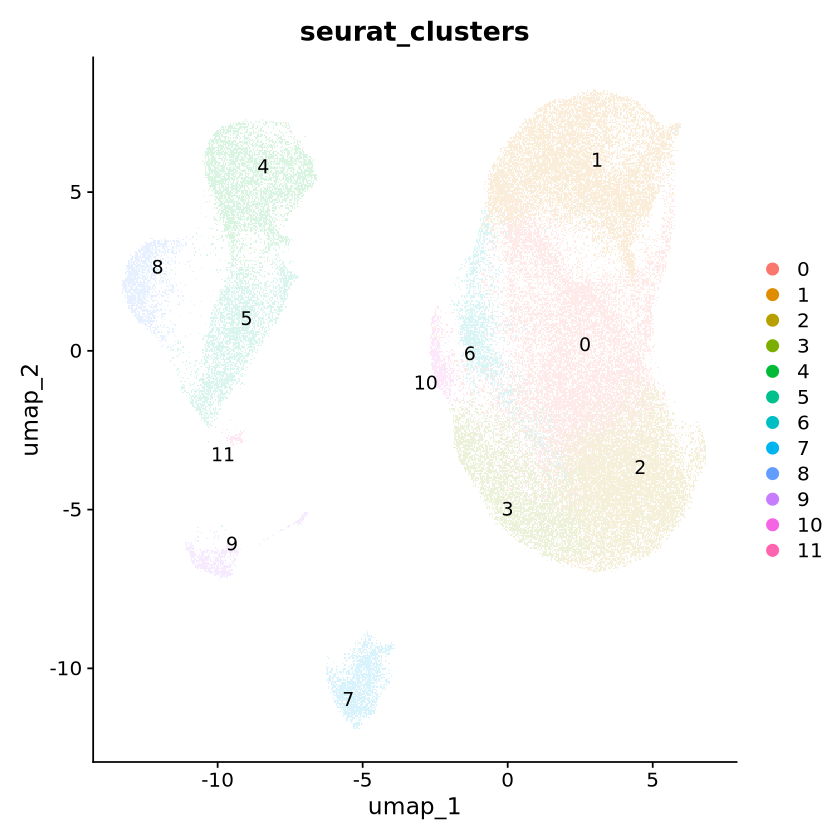

In [55]:
# Cell 25: Plot the unsupervised clusters on the UMAP
#
# This is the first direct visual assessment of whether the reconstructed
# analysis recovered coherent immune-cell populations.

DimPlot(
  object = integrated,
  reduction = "umap",
  group.by = "seurat_clusters",
  label = TRUE,
  repel = TRUE,
  raster = TRUE,
  pt.size = 0.15
)